# BÁO CÁO BÀI THỰC HÀNH 2 — CÂU 1
## Logistic Regression phân loại ngày có mưa và không mưa

Mã nguồn nộp kèm: assignment1_weather.py và logistic_regression.py.



## 1. Đề bài và phạm vi

Sử dụng dữ liệu thời tiết hằng ngày đã thu thập để:

1. Tự xây dựng Logistic Regression bằng NumPy cho hai lớp có mưa/không mưa.
2. Huấn luyện bằng Gradient Descent, đánh giá precision, recall và F1.
3. Vẽ loss theo epoch trong quá trình huấn luyện.

Mỗi mẫu là một thành phố trong một ngày. Bài toán phân loại tình trạng
mưa từ số liệu đã quan sát của cùng ngày, không phải dự báo mưa ngày
hôm sau. Các số liệu tổng hợp cả ngày chỉ có đầy đủ sau khi ngày kết thúc.

NumPy thực hiện mô hình, mã hóa đặc trưng và đánh giá. `csv`/`pathlib` chỉ
đọc dữ liệu và xử lý đường dẫn, Matplotlib vẽ, tqdm hiển thị tiến trình.


## 2. Dữ liệu, nhãn và đặc trưng
### 2.1. Dữ liệu và nhãn
Sử dụng weather_daily.csv thu thập từ Open-Meteo, gồm 9.130 mẫu
trong giai đoạn 2021–2025 tại Cần Thơ, Đà Lạt, Đà Nẵng, Hà Nội và TP.HCM.

Nhãn được tạo từ precipitation_sum: 1 — có mưa nếu giá trị lớn hơn 0,
0 — không mưa nếu bằng 0. Dữ liệu gồm 7.071 mẫu có mưa và 2.059 mẫu không mưa.

Năm đặc trưng thời tiết gồm nhiệt độ cao nhất, thấp nhất, trung bình,
thời gian có nắng và tốc độ gió lớn nhất. Không dùng precipitation_sum,
precipitation_hours và weather_code làm đầu vào để tránh dùng thông tin
trực tiếp phản ánh nhãn.
### 2.2. Chuẩn hóa và tạo đặc trưng

5 cột thời tiết: chuẩn hóa Z-score bằng trung bình và độ lệch chuẩn của tập train.</br>
2 cột tháng: mã hóa bằng sin/cos để thể hiện tính chu kỳ trong năm.</br>
4 cột thành phố: mã hóa one-hot, lấy Cần Thơ làm nhóm tham chiếu.</br>
8 cột kết hợp: nhân các cột thành phố với sin/cos của tháng để biểu diễn mùa vụ riêng theo thành phố.</br>

Tổng cộng 19 đặc trưng được dùng làm đầu vào của mô hình.

## 3. Mô hình và phương pháp huấn luyện

Bài làm sử dụng mô hình Logistic Regression trong file logistic_regression.py
. Mô hình dùng NumPy, được huấn luyện bằng Gradient Descent
và sử dụng hàm mất mát Binary Cross-Entropy.

Chương trình gọi mô hình để huấn luyện, dự đoán và đánh giá bằng precision,
recall, F1. Loss trong quá trình huấn luyện được lưu lại để vẽ đồ thị.

## 4. Chỉ số đánh giá

Các chỉ số được tự tính bằng NumPy, không dùng Scikit-learn:

$$\mathrm{Precision}=\frac{TP}{TP+FP}, \qquad
\mathrm{Recall}=\frac{TP}{TP+FN},$$

$$F1=\frac{2\,\mathrm{Precision}\,\mathrm{Recall}}
{\mathrm{Precision}+\mathrm{Recall}}.$$

TP: nhãn thật 1, dự đoán 1.</br>
FP: nhãn thật 0, dự đoán 1.</br>
FN: nhãn thật 1, dự đoán 0.</br>

Nếu mẫu số bằng 0, code trả chỉ số tương ứng bằng 0 để tránh phép chia
không xác định. Đây là các chỉ số của lớp dương, không phải macro average
của cả hai lớp. F1 không phải accuracy.

## 5. Thiết kế thực nghiệm

Chia dữ liệu theo thời gian:

Train: năm 2021–2023, 5.475 mẫu.</br>
Validation: năm 2024, 1.830 mẫu.</br>
Test: năm 2025, 1.825 mẫu.</br>

Giữ learning rate 0.1, thử 100, 500, 1.000 epoch và ngưỡng
0.10–0.90, bước 0.05. Chọn mô hình và ngưỡng có F1 cao nhất
trên validation, sau đó đánh giá trên test.

## 6. Kết quả

Training: 100%|██████████| 1000/1000 [00:02<00:00, 482.71it/s, loss=0.338]


precision:	0.8977
recall:	0.9176
f1:	0.9075


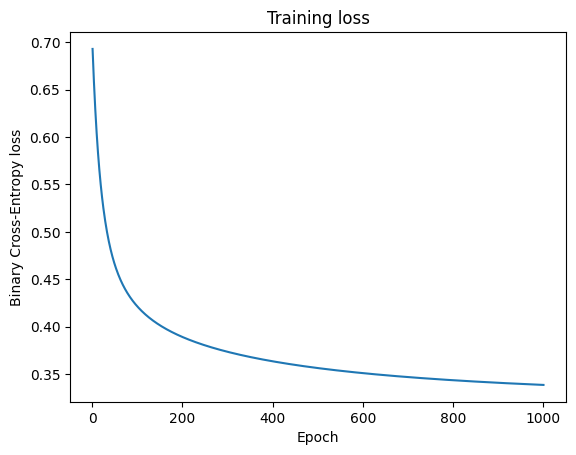

<Figure size 640x480 with 0 Axes>

In [ ]:
%matplotlib inline
%run "/content/assignment1_weather(1).py"